# Question:

## In a game of Magic: The Gathering, what are the chances of pulling the Elusive Otter and the Kinetic Ooze in a starting hand

Descripton:

1. The random process I am simulating is drawing one card from the top of my 99-card deck, without replacement.
2. One trial in my simulation is drawing one card, then another. The possible outcomes are any seven cards from the Quandrix Unlimited deck list, not including the commander
3. I will be trying to measure the chances of drawing the Elusive Otter and Kinetic Ooze creature cards
4. I will call getting the elusive otter A and getting the kinetic ooze B
5. My question is asking for P(A n B) this is joint probability
6. Events A and B are not mutually exclusive because getting one of them does not stop me from getting the other

In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [19]:
# Create a 99-card deck
deck = list(range(1, 100))

In [20]:
# Card numbers
elusive_otter = 5
kinetic_ooze = 13

In [21]:
# Number of simulations
trials = 10000

In [22]:
# Counters
otter_count = 0
ooze_count = 0
both_count = 0

In [23]:
# Run the simulation
for i in range(trials):

    # Draw a starting hand of 7 cards
    hand = pd.Series(deck).sample(n=7, replace=False)

    # Check for the two cards
    has_otter = elusive_otter in hand.values
    has_ooze = kinetic_ooze in hand.values

    if has_otter:
        otter_count += 1

    if has_ooze:
        ooze_count += 1

    if has_otter and has_ooze:
        both_count += 1

In [24]:
# Calculate probabilities
otter_probability = otter_count / trials
ooze_probability = ooze_count / trials
both_probability = both_count / trials

In [25]:
# Display results in a DataFrame
results = pd.DataFrame({
    "Event": ["Elusive Otter", "Kinetic Ooze", "Both Cards"],
    "Count": [otter_count, ooze_count, both_count],
    "Probability": [
        otter_probability,
        ooze_probability,
        both_probability
    ]
})

In [26]:
# Theoretical probabilities
deck_size = 99
hand_size = 7

In [27]:
# Probability of drawing a specific card
theoretical_otter = hand_size / deck_size

In [28]:
# Probability of drawing a specific card
theoretical_ooze = hand_size / deck_size

In [29]:
# Probability of drawing both cards
theoretical_both = (hand_size / deck_size) * ((hand_size - 1) / (deck_size - 1))

In [30]:
print("\nTheoretical Probabilities")
print(f"Elusive Otter: {theoretical_otter:.4f}")
print(f"Kinetic Ooze: {theoretical_ooze:.4f}")
print(f"Both Cards: {theoretical_both:.4f}")


Theoretical Probabilities
Elusive Otter: 0.0707
Kinetic Ooze: 0.0707
Both Cards: 0.0043


In [31]:
results["Theoretical Probability"] = [
    theoretical_otter,
    theoretical_ooze,
    theoretical_both
]

print(results)

           Event  Count  Probability  Theoretical Probability
0  Elusive Otter    723       0.0723                 0.070707
1   Kinetic Ooze    717       0.0717                 0.070707
2     Both Cards     38       0.0038                 0.004329


In [32]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

<Figure size 1000x500 with 0 Axes>

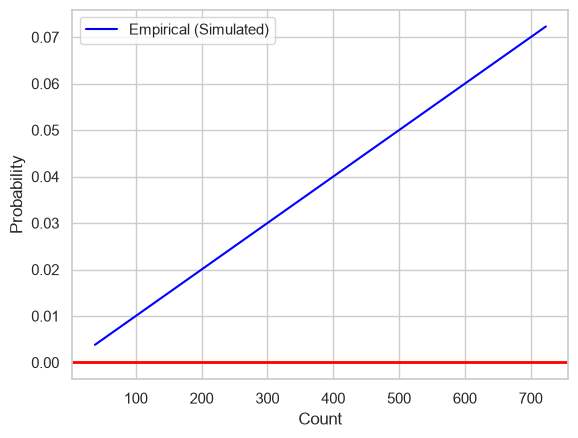

In [53]:
sns.lineplot(data=results, x="Count", y="Probability", label="Empirical (Simulated)", color="blue", linewidth=1.5,)
plt.axhline(color="red", linewidth=2, label='Theoretical Probability',)

In [ ]:
plt.title("Empirical vs. Theoretical Probability (Law of Large Numbers)")
plt.xlabel("Number of Trials")
plt.ylabel("Probability of Heads")
plt.ylim(0, 1)  # Probabilities range from 0 to 1
plt.legend(loc="upper right")

plt.show()

# Conclusion:

The chances of both the elusive otter and kinetic ooze being in a starting hand of magic are around .004 percent, which almost lines up with our theoretical probability of around .004 percent